In [1]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm



In [7]:
data_dir + '/' + site + '/20*' + corr_str + '/' + 'moment*.csv'

'D:/!Work/IFA/Tomsk project/Tomsk AMK data//BEK/20*_test2/moment*.csv'

In [5]:

data_dir = 'D:/!Work/IFA/Tomsk project/Tomsk AMK data/'
#sites = ['BEK', 'Oblkom', 'IMCES_40m', 'IMCES_30m', 'IMCES_MEZO_30m']
sites = ['BEK', 'Oblkom']#, 'IMCES_40m', 'IMCES_MEZO_30m']



df = pd.DataFrame()

corr_str = '_test2'

for site in sites:
    display(site)
    df4site = pd.DataFrame()
    for file in tqdm (glob.glob(data_dir + '/' + site + '/20*' + corr_str + '/' + 'moment*.csv')):
    #for file in tqdm (glob.glob(data_dir + '/' + site + '/20*/' + 'moment*.csv')):
    
        cur_df = pd.read_csv (file, sep = ';')
        cur_df['datetime'] = [pd.to_datetime(x, dayfirst=True) for x in cur_df['data']]
        cur_df = cur_df.sort_values(by='datetime').set_index('datetime')
        for c in cur_df.columns:
            if c not in ['N', 'data']:
                cur_df[c] = cur_df[c].astype(float)
        
        if 'uz' not in cur_df.columns:
            #print ('aaa')
            cur_df['uz'] = np.sqrt (cur_df['uw']**2 + cur_df['vw']**2)
            
        df4site = pd.concat((df4site, cur_df))

    #df4site['V_old'] = df4site['V']
    df4site['V'] = np.sqrt(df4site['u']**2 + df4site['v']**2)
    df4site['rho'] = df4site['tau'] / (df4site['uz'] ** 2)
    df4site['Cd'] = (df4site['uz'] / df4site['V']) **2
    
    #ustar2u_ratio = df4site['uz'] / df4site['V']
    #display(ustar2u_ratio.quantile(0.99))
    #df4site.loc[ustar2u_ratio > 1, 'Cd'] = np.nan
    
    df4site = df4site.rename(columns={c: site + '_' + c for c in df4site.columns})
    df = df.merge(df4site, how = 'outer', right_index = True, left_index = True)        

time_arr = pd.date_range(pd.Timestamp(df.index.date[0]), pd.Timestamp(df.index.date[-1]), freq = '20min') 
df = df.resample('20min').last() 
df = df.reindex(time_arr)


'BEK'

0it [00:00, ?it/s]


KeyError: 'u'

### Data availibility plot

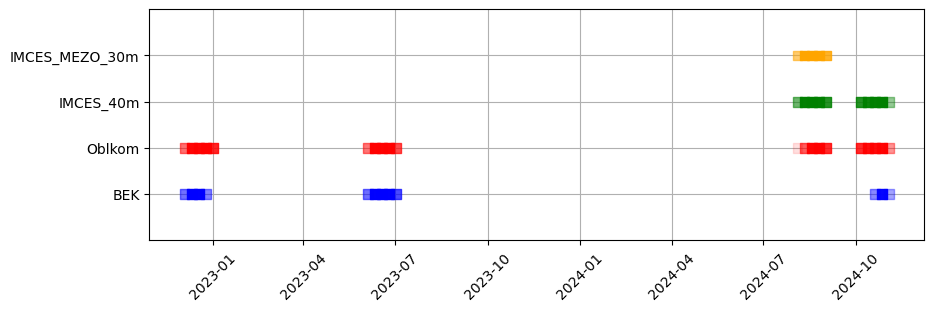

In [15]:
site_colors = {'BEK': 'blue', 
               'IMCES_40m': 'green', 
               'IMCES_30m': 'limegreen',
               'IMCES_MEZO_30m': 'orange', 
               'Oblkom': 'red'}

plt.figure(figsize=(10,3))
plt.grid(zorder=0)



for i, site in enumerate(sites):
    counts = df[site + '_t'].resample('w').count()
    plt.scatter(counts.index, np.ones_like(counts)*i, np.ones_like(counts)*50, marker='s', alpha=counts/counts.max(), label = site,  zorder=10, color = site_colors[site])

plt.gca().set_yticks(range(0,len(sites)))
plt.gca().set_yticklabels(sites) #range(0,len(sites)))
plt.gca().set_ylim((-1,len(sites)))
_ = plt.xticks(rotation = 45)


### Filter data and select days with low gaps ratio

['Oblkom', 'BEK']

['Oblkom', 'BEK', 'IMCES_40m']

['Oblkom', 'IMCES_40m']

['Oblkom', 'IMCES_40m', 'IMCES_MEZO_30m']

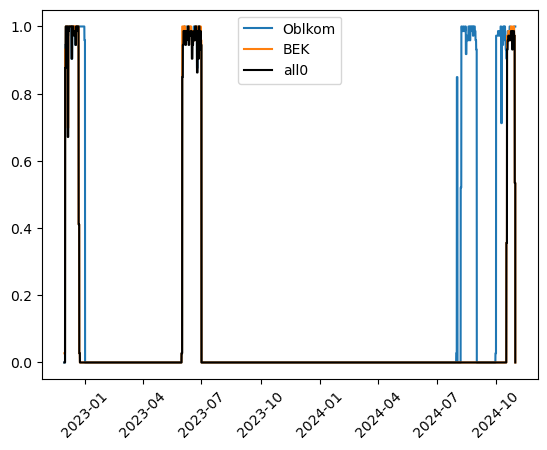

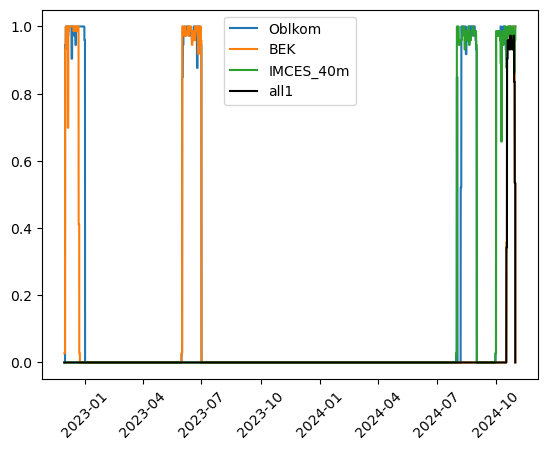

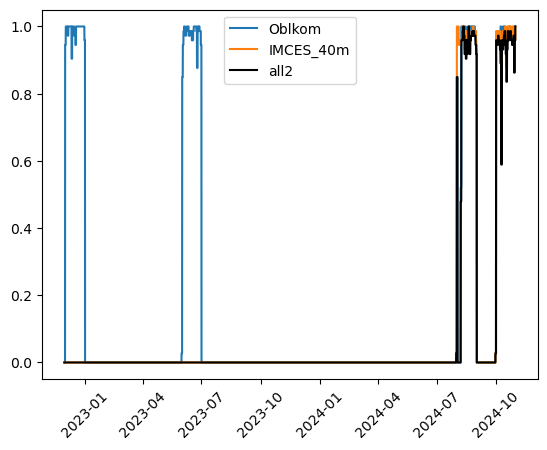

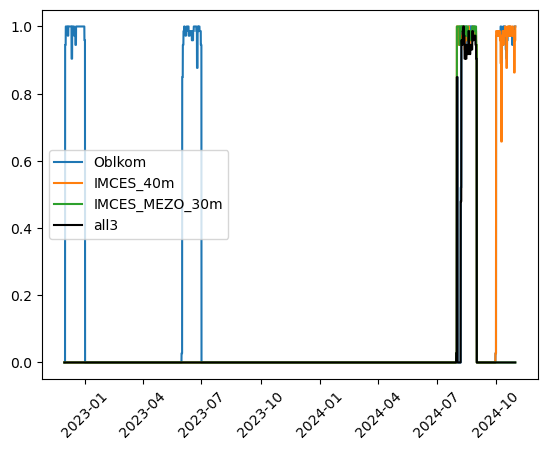

In [16]:
#matplotlib inline
#%matplotlib qt


def is_ok4day (df, unique_dates, is_ok_name):
    df['is_ok4day_' + is_ok_name] = np.zeros((df.shape[0],1))
    for unique_date in unique_dates:
        sel_times = slice (pd.Timestamp(unique_date), pd.Timestamp(unique_date) + pd.Timedelta(days=1))
        n = df[sel_times].shape[0]
        n_ok = np.sum(df[sel_times]['is_ok_' + is_ok_name])
        df.loc[sel_times, 'is_ok4day_' + is_ok_name] = n_ok/n
    return df

#sites2draw_sets = [['Oblkom', 'BEK'], ['Oblkom', 'BEK', 'IMCES_40m'], ['Oblkom', 'IMCES_40m'], ['Oblkom', 'IMCES_30m', 'IMCES_40m'],  ['Oblkom', 'IMCES_MEZO_30m', 'IMCES_40m'], ['Oblkom', 'IMCES_30m', 'IMCES_40m', 'IMCES_MEZO_30m']]
sites2draw_sets = [['Oblkom', 'BEK'], ['Oblkom', 'BEK', 'IMCES_40m'], ['Oblkom', 'IMCES_40m'], ['Oblkom', 'IMCES_40m', 'IMCES_MEZO_30m']]

unique_dates = np.unique(df.index.date)

vars2draw = ['t', 'V', 'w', 'tau', 'H', 'Cd']
filter_vars = ['H', 'tau', 'Cd']
filter_lims = {'H': [-500, 1000], 'tau': [0, 4], 'Cd': [0, 1]}

for site in sites:
    outlier_idx = []

    for var in filter_vars:
        var_f = df[site + '_' + var].copy()
        if var in filter_lims.keys():
            var_f[var_f < filter_lims[var][0]] = np.nan
            var_f[var_f > filter_lims[var][1]] = np.nan
        var_rol_mean =  var_f.rolling(3*24*30, center=True, min_periods=1).mean()
        var_rol_std  =  var_f.rolling(3*24*30, center=True, min_periods=1).std()
        lim1 = var_rol_mean - 5 * var_rol_std
        lim2 = var_rol_mean + 5 * var_rol_std

        var_f[(var_f < lim1) | (var_f > lim2)] = np.nan
        cur_outlier_idx = np.where(~np.isnan(df[site + '_' + var]) & np.isnan(var_f))[0].tolist()
        outlier_idx = outlier_idx + cur_outlier_idx

        # if var == 'Cd':
        #     plt.figure()
        #     plt.plot (df.index, df[site + '_' + var])
        #     plt.plot (df.index[cur_outlier_idx], df[site + '_' + var].iloc[cur_outlier_idx], 'ok')
        #     plt.title(site + ', ' + var)
    outlier_idx = np.unique(outlier_idx)
    remove_idx = []
    for i in outlier_idx:
        remove_idx += np.arange(np.max([0, i - 3]), np.min([i+3, df.shape[0]])).tolist()
    remove_idx = np.unique(outlier_idx)

    df[site + '_filter_passed'] = np.ones_like (df[site + '_H'])
    df[site + '_filter_passed'] = df[site + '_filter_passed'].astype(bool)
    df.loc[df.index[remove_idx], site + '_filter_passed'] = False

    #             remove_idx += list(idx)
    #display(outlier_idx)
    #continue
    # for var in vars2draw:
    #     if site + '_' + var + '_raw' not in df.columns:
    #         df[site + '_' + var + '_raw'] = df[site + '_' + var]
    #     else:
    #         df[site + '_' + var] = df[site + '_' + var + '_raw']
        
    #     for i in range (0, df.shape[0]):
    #         if np.abs(df[site + '_H'].iloc[i]) > 1000:
    #             filter_passed = False
    #         else:
    #             filter_passed = True
            
    #         if not filter_passed:
    #             idx = np.arange(np.max([0, i - 20]), np.min([i+20, df.shape[0]]))
    #             remove_idx += list(idx)
                
    for var in vars2draw:
        #filter_var = df[site + '_' + var].copy()
        #df.loc[df.index[remove_idx], site + '_' + var] = np.nan
        df['is_ok_' + site] = np.logical_and.reduce([~np.isnan(df[site + '_' + var]) & df[site + '_filter_passed'] for var in vars2draw])

    df = is_ok4day (df, unique_dates, site)
    # df['is_ok4day_' + site] = np.zeros((df.shape[0],1))
    # for unique_date in unique_dates:
    #     sel_times = slice (pd.Timestamp(unique_date), pd.Timestamp(unique_date) + pd.Timedelta(days=1))
    #     n = df[sel_times].shape[0]
    #     n_ok = np.sum(df[sel_times]['is_ok_' + site])
    #     df.loc[sel_times, 'is_ok4day_' + site] = n_ok/n

for i, sites2draw in enumerate(sites2draw_sets):
    display(sites2draw)
    df['is_ok_all' + str(i)] = np.logical_and.reduce([df['is_ok_' + site] for site in sites2draw])
    df = is_ok4day (df, unique_dates, 'all' + str(i))

    plt.figure()
    for site in sites2draw:
        plt.plot (df['is_ok4day_' + site], label = site)
    plt.plot(df['is_ok4day_all' + str(i)], color='black', label = 'all' + str(i))
    plt.legend()
    _ = plt.xticks(rotation = 45)

In [17]:
plt.rcParams["font.size"] = 10

from calendar import monthrange
import matplotlib.ticker
#periods = [slice(pd.Timestamp(2022,m,1),pd.Timestamp(2022,m,1) + pd.Timedelta (days = monthrange(2022,m)[1]) - pd.Timedelta (hours=1)) for m in [11,12]] + \
#          [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [5,6,7]]


#periods = [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [7, 8,11,12]] + \
#          [slice(pd.Timestamp(2024,m,1),pd.Timestamp(2024,m,1) + pd.Timedelta (days = monthrange(2024,m)[1]) - pd.Timedelta (hours=1)) for m in [1,6]] #+ [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [5,6,7]]

# periods = [slice(pd.Timestamp(2022,m,1),pd.Timestamp(2022,m,1) + pd.Timedelta (days = monthrange(2022,m)[1]) - pd.Timedelta (hours=1)) for m in range(12,13)] + \
#           [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in range(5,13)]  + \
#           [slice(pd.Timestamp(2024,m,1),pd.Timestamp(2024,m,1) + pd.Timedelta (days = monthrange(2024,m)[1]) - pd.Timedelta (hours=1)) for m in range(1,9)] #+ \
#           #[slice(pd.Timestamp(2024,8,1),pd.Timestamp(2024,8,6), slice(pd.Timestamp(2024,8,8),pd.Timestamp(2024,9,1)))]


periods = [slice(pd.Timestamp(2024,10,1),pd.Timestamp(2024,11,1))]

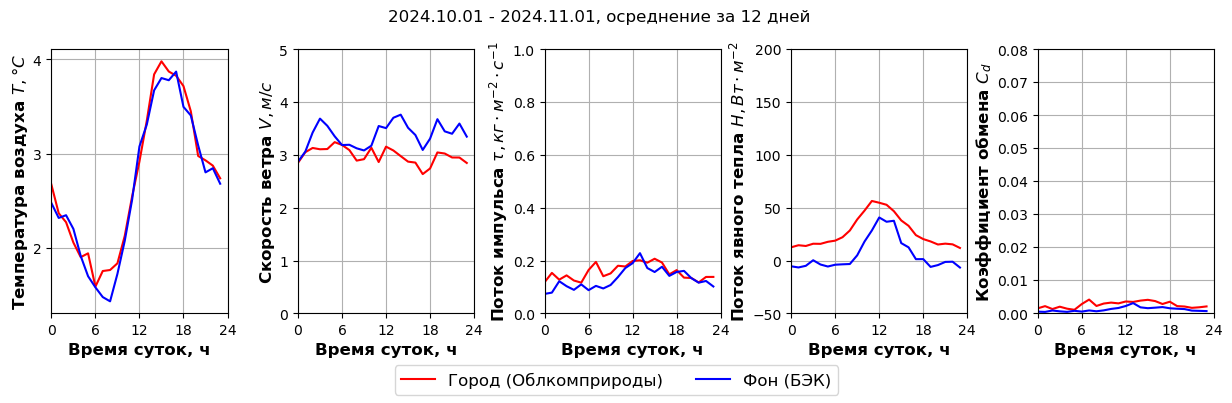

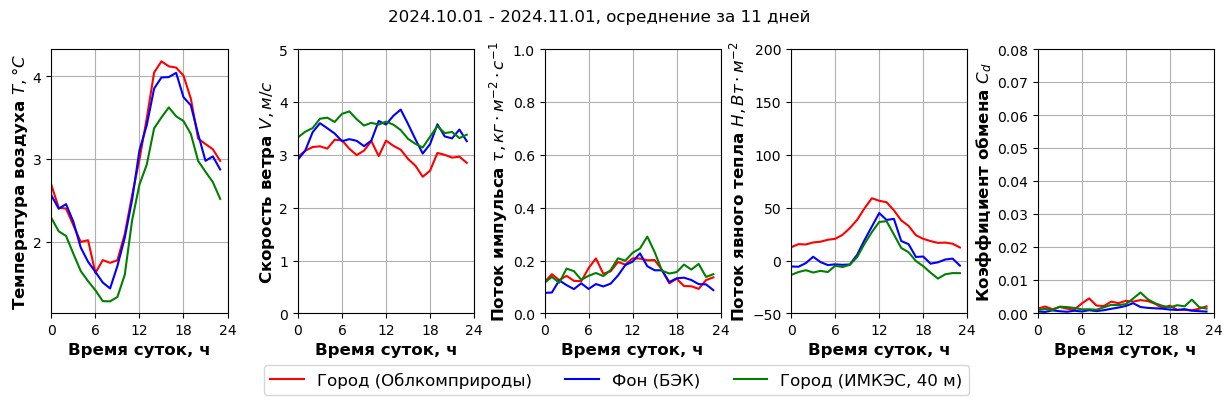

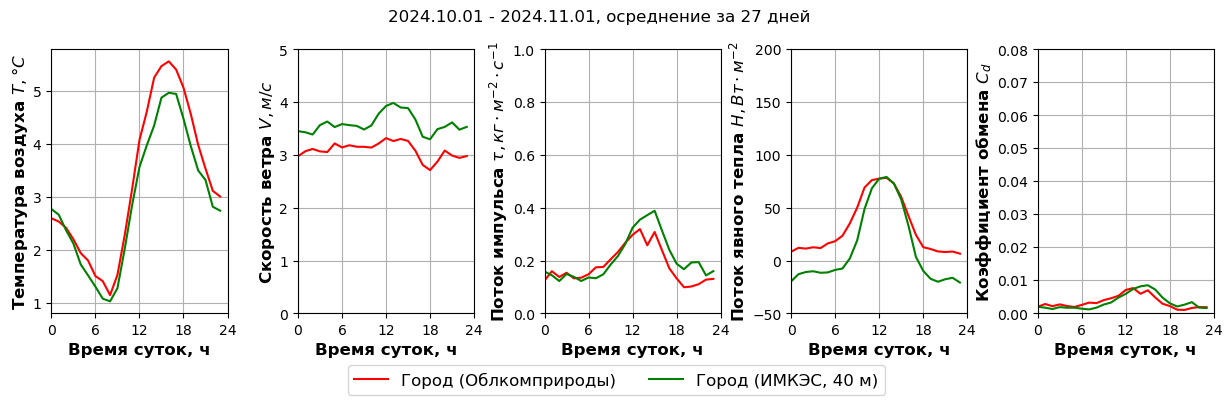

In [18]:
%matplotlib inline
vars2draw_labels = {'t'  : 'Температура воздуха $T, °C$', 
                    'V'  : 'Скорость ветра $V, м/с$',
                    #'w'  : 'Верт. скорость ветра, м/с',
                    'tau': 'Поток импульса $\\tau, кг\\cdot м^{-2}\\cdot c^{-1}$',
                    'H'  : 'Поток явного тепла $H, Вт\\cdotм^{-2}$',
                    'Cd' : 'Коэффициент обмена $C_d$'}

site_names2draw = {'BEK':'Фон (БЭК)',
                   'IMCES_40m': 'Город (ИМКЭС, 40 м)', 
                   'IMCES_30m': 'Город (ИМКЭС, 30 м)',
                   'IMCES_MEZO_30m': 'Город (ИМКЭС, мезонин, 30 м)', 
                   'Oblkom': 'Город (Облкомприроды)'}

site_colors = {'BEK': 'blue', 
               'IMCES_40m': 'green', 
               'IMCES_30m': 'limegreen',
               'IMCES_MEZO_30m': 'orange', 
               'Oblkom': 'red'}

# site_colors = {'BEK': 'black', 
#                'IMCES_40m': 'black', 
#                'IMCES_30m': 'black',
#                'IMCES_MEZO_30m': 'black', 
#                'Oblkom': 'gray'}

# site_styles = {'BEK': '--', 
#                'IMCES_40m': '--', 
#                'IMCES_30m': ':',
#                'IMCES_MEZO_30m': ':', 
#                'Oblkom': '-'} 

site_styles = {'BEK': '-', 
               'IMCES_40m': '-', 
               'IMCES_30m': '-',
               'IMCES_MEZO_30m': '-', 
               'Oblkom': '-'} 

vars2draw = list(vars2draw_labels.keys())

save_dir = 'pics_new/'
#save_dir = 'pics4paper2_BW' + corr_str + '/'


if not os.path.isdir(save_dir):
    os.mkdir (save_dir)

valid_data_frac = 0.9

for period in periods:

    df_sel = df[period]

    is_ok_count = np.zeros(len(sites2draw_sets))
    is_ok4sets = []
    for i_set, sites2draw_set in enumerate(sites2draw_sets):
        is_ok = df_sel['is_ok4day_all' + str(i_set)] > valid_data_frac
        is_ok_count[i_set] = np.sum(is_ok)
        is_ok4sets.append(is_ok)


    for i_set, sites2draw in enumerate(sites2draw_sets):
        if is_ok_count[i_set] == 0:
            continue
    
        is_ok = is_ok4sets[i_set]

        ok_idx  = np.where(is_ok)[0]
        bad_idx = np.where(~is_ok)[0]

        df_sel2 = df_sel.iloc[ok_idx, :]

        n_days = len(np.unique(df_sel2.index.date))

        #fig_name = '%s - %s, sites = %s'%(str(period.start.strftime('%Y.%m.%d'), str(period.stop.strftime('%Y.%m.%d'), str(sites2draw))))
        fig_name = '%s - %s, sites = %s, lim = %.2f'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d')), str(sites2draw), valid_data_frac)
        
        
        for show_raw_data in [False,True]:
            fig, ax = plt.subplots(len(vars2draw), 1,  figsize = (10, 2.5* len(vars2draw)), sharex=True) 
            for i, var in enumerate(vars2draw):
                for site in sites2draw:
                    #df_sel[site + '_' + var].plot(ax = ax[i])
                    data_raw = df_sel[site + '_' + var]
                    data_filtered = data_raw.copy()
                    data_filtered [~df_sel[site + '_filter_passed']] = np.nan
                    p = ax[i].plot (df_sel.index, data_filtered, label = site, color = site_colors[site])
                    if show_raw_data:
                        c = p[0].get_color()
                        p = ax[i].plot (df_sel.index, data_raw, color = c, alpha = 0.5)
                        #ax[i].plot(df_sel.index[~df_sel[site + '_filter_passed']], data_raw [site + '_filter_passed'], 'ok')
                    
                ax[i].set_ylabel(vars2draw_labels[var])
                y_lim = list(ax[i].get_ylim())
                
                # if var == 'H' and period.start.month == 6:
                #     y_lim = [-200, 600]
                # elif var == 'tau' and period.start.month == 6:
                #     y_lim = [0, 4]
                # elif var == 'Cd' and period.start.month == 6:
                #     y_lim = [0, 1]

                
                ok_indicator = np.ones_like(df_sel['is_ok4day_all' + str(i_set)])
                ok_indicator[bad_idx] = np.nan
        
                ax[i].fill_between (df_sel.index, ok_indicator*y_lim[0], ok_indicator*y_lim[1], alpha = 0.25, color = 'green') 
                ax[i].set_ylim(y_lim)
                ax[i].set_xlim((period.start, period.stop))

            plt.suptitle('%s - %s'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d'))))
            plt.legend()
            plt.savefig (save_dir + 'ts' + fig_name + '_raw=%d'%show_raw_data + corr_str + '.png', dpi=300)
            plt.close()

        fig, ax = plt.subplots(1, len(vars2draw), figsize = (2.5 * len(vars2draw), 4))
        df4fig = pd.DataFrame()
        for i, var in enumerate(vars2draw):
            for site in sites2draw:
                data_raw = df_sel2[site + '_' + var]
                data_filtered = data_raw.copy()
                data_filtered [~df_sel[site + '_filter_passed']] = np.nan

                hour_means = data_filtered.groupby([df_sel2.index.hour]).mean()
                hour_stds = data_filtered.groupby([df_sel2.index.hour]).std()
                
                df4fig[var + '_' + site] = hour_means
                #ax[i].fill_between(hour_means.index, hour_means - hour_stds, hour_means + hour_stds, color = site_colors[site], alpha = 0.5)
                ax[i].plot(hour_means.index, hour_means, label=site_names2draw[site], color = site_colors[site], linestyle = site_styles[site]) 
                
                if var == 'w':
                    ax[i].plot(hour_means.index, hour_stds, '--', label=site_names2draw[site], color = site_colors[site]) 
                
            #if i == 0:
            #ax[i].set_title(var)
            ax[i].set_ylabel(vars2draw_labels[var], labelpad = 2, fontsize=12, fontweight='bold')
            ax[i].set_xticks(np.arange(0,24+1,6)) 
            ax[i].set_xlabel('Время суток, ч', fontsize=12, fontweight='bold')
            ax[i].set_xlim((0,24))

            y_lim = list(ax[i].get_ylim())
            if var in ['Cd', 'tau', 'V']:
                y_lim[0] = 0

            if var == 'V':
                y_lim = [0,5]
            elif var == 'w':
                y_lim = [-0.6,0.6]
            elif var == 'H':
                y_lim = [-50, 200]

            elif var == 'tau':
                y_lim = [0,1]
            elif var == 'Cd':
                y_lim = [0,0.08]
            
            ax[i].set_ylim(y_lim)

            if var == 't':
                ax[i].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(1))

            ax[i].grid(zorder=0)

        handles, labels = ax[0].get_legend_handles_labels()
        plt.figlegend(handles, labels, loc="lower center", ncol=len (sites2draw), fontsize=12)
            
            
        plt.subplots_adjust (left = 0.06, wspace = 0.4, right = 0.99, bottom = 0.22)
        
        plt.suptitle('%s - %s, осреднение за %d дней '%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d')), n_days))
        plt.savefig (save_dir + 'mean_diurnal_turn_' + fig_name + corr_str + '.png', dpi=300)
        
        df4fig.to_csv (save_dir + 'mean_diurnal_turn_' + fig_name + corr_str + '.csv', sep=';')
    #break



In [31]:
%matplotlib qt
plt.rcParams["font.size"] = 20

plt.figure()
plt.plot(df.index, df['IMCES_40m_H'], color = 'orange')
# ax[1].plot(df.index, df['IMCES_30m_H'], color = 'brown')
plt.plot(df.index, df['Oblkom_H'], color = 'red')

# ax[0].plot(df.index, df['Oblkom_H'], color = 'red')
#fig, ax = plt.subplots (3,1,sharex=True)
# ax[0].plot(df.index, df['BEK_tau'], color = 'blue')
# ax[0].plot(df.index, df['IMCES_40m_tau'], color = 'orange')
# ax[0].plot(df.index, df['IMCES_30m_tau'], color = 'brown')
# ax[0].plot(df.index, df['Oblkom_tau'], color = 'red')
# ax[0].set_ylabel('tau')

#ax[1].plot(df.index, df['BEK_H'], color = 'blue')
# ax[1].plot(df.index, df['IMCES_40m_H'], color = 'orange')
# ax[1].plot(df.index, df['IMCES_30m_H'], color = 'brown')
# ax[1].plot(df.index, df['Oblkom_H'], color = 'red')
# ax[1].set_ylabel('H')

# ax[2].plot(df.index, df['BEK_w'], color = 'blue')
# ax[2].plot(df.index, df['IMCES_40m_w'], color = 'orange')
# ax[2].plot(df.index, df['IMCES_30m_w'], color = 'brown')
# ax[2].plot(df.index, df['Oblkom_w'], color = 'red')
# ax[2].set_ylabel('w')
